In [1]:
# L'importation des outils requis

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

In [2]:
# Ouvrir le fichier csv et lire les premier 5 lignes avec .head()

df = pd.read_csv("Crime_Data_from_2020_to_Present.csv")
#df = pd.read_csv( """ Clicker sur le "Copy Path" de le csv pour le travaille et le copier ici """ )

df.head()

,DR_NO,Date Rptd,DATE OCC,TIME OCC,AREA,AREA NAME,Rpt Dist No,Part 1-2,Crm Cd,Crm Cd Desc,...,Status,Status Desc,Crm Cd 1,Crm Cd 2,Crm Cd 3,Crm Cd 4,LOCATION,Cross Street,LAT,LON
0,190326475,03/01/2020 12:00:00 AM,03/01/2020 12:00:00 AM,2130,7,Wilshire,784,1,510,VEHICLE - STOLEN,...,AA,Adult Arrest,510.0,998.0,NaN,NaN,1900 S LONGWOOD AV,NaN,34.0375,-118.3506
1,200106753,02/09/2020 12:00:00 AM,02/08/2020 12:00:00 AM,1800,1,Central,182,1,330,BURGLARY FROM VEHICLE,...,IC,Invest Cont,330.0,998.0,NaN,NaN,1000 S FLOWER ST,NaN,34.0444,-118.2628
2,200320258,11/11/2020 12:00:00 AM,11/04/2020 12:00:00 AM,1700,3,Southwest,356,1,480,BIKE - STOLEN,...,IC,Invest Cont,480.0,NaN,NaN,NaN,1400 W 37TH ST,NaN,34.0210,-118.3002
3,200907217,05/10/2023 12:00:00 AM,03/10/2020 12:00:00 AM,2037,9,Van Nuys,964,1,343,SHOPLIFTING-GRAND THEFT ($950.01 & OVER),...,IC,Invest Cont,343.0,NaN,NaN,NaN,14000 RIVERSIDE DR,NaN,34.1576,-118.4387
4,220614831,08/18/2022 12:00:00 AM,08/17/2020 12:00:00 AM,1200,6,Hollywood,666,2,354,THEFT OF IDENTITY,...,IC,Invest Cont,354.0,NaN,NaN,NaN,1900 TRANSIENT,NaN,34.0944,-118.3277


In [3]:
# Visionner tous les noms des colonnes pour être capable de comprendre quoi modifier

df.columns

Index(['DR_NO', 'Date Rptd', 'DATE OCC', 'TIME OCC', 'AREA', 'AREA NAME',
       'Rpt Dist No', 'Part 1-2', 'Crm Cd', 'Crm Cd Desc', 'Mocodes',
       'Vict Age', 'Vict Sex', 'Vict Descent', 'Premis Cd', 'Premis Desc',
       'Weapon Used Cd', 'Weapon Desc', 'Status', 'Status Desc', 'Crm Cd 1',
       'Crm Cd 2', 'Crm Cd 3', 'Crm Cd 4', 'LOCATION', 'Cross Street', 'LAT',
       'LON'],
      dtype='object')

In [4]:
# Le commencement de le nettoyage des noms

# str.lower est pour fair remplacer tous les majiscule en miniscule,
# et le str.replace est pour remplacer un caractère spécifique.

df.columns = df.columns.str.lower().str.replace('-','_').str.replace(' ','_')

# Après tous est finis, revisionner les colonnes pour confirmer tous les modifications on marcher

df.columns

Index(['dr_no', 'date_rptd', 'date_occ', 'time_occ', 'area', 'area_name',
       'rpt_dist_no', 'part_1_2', 'crm_cd', 'crm_cd_desc', 'mocodes',
       'vict_age', 'vict_sex', 'vict_descent', 'premis_cd', 'premis_desc',
       'weapon_used_cd', 'weapon_desc', 'status', 'status_desc', 'crm_cd_1',
       'crm_cd_2', 'crm_cd_3', 'crm_cd_4', 'location', 'cross_street', 'lat',
       'lon'],
      dtype='object')

In [5]:
# Pour regarder les colonnes et leur type, on a besoin de utiliser dtypes, qui va nous donner les types de chaque variable

df.dtypes

dr_no               int64
date_rptd          object
date_occ           object
time_occ            int64
area                int64
area_name          object
rpt_dist_no         int64
part_1_2            int64
crm_cd              int64
crm_cd_desc        object
mocodes            object
vict_age            int64
vict_sex           object
vict_descent       object
premis_cd         float64
premis_desc        object
weapon_used_cd    float64
weapon_desc        object
status             object
status_desc        object
crm_cd_1          float64
crm_cd_2          float64
crm_cd_3          float64
crm_cd_4          float64
location           object
cross_street       object
lat               float64
lon               float64
dtype: object

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 982638 entries, 0 to 982637
Data columns (total 28 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   dr_no           982638 non-null  int64  
 1   date_rptd       982638 non-null  object 
 2   date_occ        982638 non-null  object 
 3   time_occ        982638 non-null  int64  
 4   area            982638 non-null  int64  
 5   area_name       982638 non-null  object 
 6   rpt_dist_no     982638 non-null  int64  
 7   part_1_2        982638 non-null  int64  
 8   crm_cd          982638 non-null  int64  
 9   crm_cd_desc     982638 non-null  object 
 10  mocodes         837376 non-null  object 
 11  vict_age        982638 non-null  int64  
 12  vict_sex        844193 non-null  object 
 13  vict_descent    844182 non-null  object 
 14  premis_cd       982624 non-null  float64
 15  premis_desc     982053 non-null  object 
 16  weapon_used_cd  326167 non-null  float64
 17  weapon_des

In [7]:
completeness = (1 - df.isna().mean()) * 100
for c in df.columns:
    if df[c].dtype.name in ('category','object'):
        pass
print(completeness.sort_values().to_string())

crm_cd_4            0.006513
crm_cd_3            0.235183
crm_cd_2            7.009194
cross_street       15.453198
weapon_used_cd     33.192997
weapon_desc        33.192997
mocodes            85.217140
vict_descent       85.909765
vict_sex           85.910885
premis_desc        99.940466
premis_cd          99.998575
crm_cd_1           99.998881
status             99.999898
dr_no             100.000000
date_occ          100.000000
date_rptd         100.000000
crm_cd_desc       100.000000
crm_cd            100.000000
vict_age          100.000000
time_occ          100.000000
area              100.000000
area_name         100.000000
rpt_dist_no       100.000000
part_1_2          100.000000
status_desc       100.000000
location          100.000000
lat               100.000000
lon               100.000000


In [8]:
# La fonction drop qui est utiliser pour enlever les colonnes inutiles

df = df.drop(["date_rptd", "rpt_dist_no", "area_name", "weapon_desc", "crm_cd_desc", "premis_desc", "weapon_desc", "status_desc", "crm_cd_1", "crm_cd_2", "crm_cd_3", "crm_cd_4", "location", "cross_street","lat","lon"], axis= 1)

In [9]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 982638 entries, 0 to 982637
Data columns (total 13 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   dr_no           982638 non-null  int64  
 1   date_occ        982638 non-null  object 
 2   time_occ        982638 non-null  int64  
 3   area            982638 non-null  int64  
 4   part_1_2        982638 non-null  int64  
 5   crm_cd          982638 non-null  int64  
 6   mocodes         837376 non-null  object 
 7   vict_age        982638 non-null  int64  
 8   vict_sex        844193 non-null  object 
 9   vict_descent    844182 non-null  object 
 10  premis_cd       982624 non-null  float64
 11  weapon_used_cd  326167 non-null  float64
 12  status          982637 non-null  object 
dtypes: float64(2), int64(6), object(5)
memory usage: 97.5+ MB


In [10]:
# La fonction est utiliser pour regarder si il a des doublons

df[df.duplicated()]

,dr_no,date_occ,time_occ,area,part_1_2,crm_cd,mocodes,vict_age,vict_sex,vict_descent,premis_cd,weapon_used_cd,status


In [11]:
df.describe()

,dr_no,time_occ,area,part_1_2,crm_cd,vict_age,premis_cd,weapon_used_cd
count,9.826380e+05,982638.000000,982638.000000,982638.000000,982638.000000,982638.000000,982624.000000,326167.000000
mean,2.197437e+08,1338.945426,10.700277,1.404253,500.823555,29.079817,306.133008,363.840882
std,1.294954e+07,651.537830,6.107808,0.490747,206.211940,21.970094,219.053795,123.684663
min,8.170000e+02,1.000000,1.000000,1.000000,110.000000,-4.000000,101.000000,101.000000
25%,2.106089e+08,900.000000,5.000000,1.000000,331.000000,0.000000,101.000000,311.000000
50%,2.208146e+08,1420.000000,11.000000,1.000000,442.000000,30.000000,203.000000,400.000000
75%,2.309153e+08,1900.000000,16.000000,2.000000,626.000000,44.000000,501.000000,400.000000
max,2.499253e+08,2359.000000,21.000000,2.000000,956.000000,120.000000,976.000000,516.000000


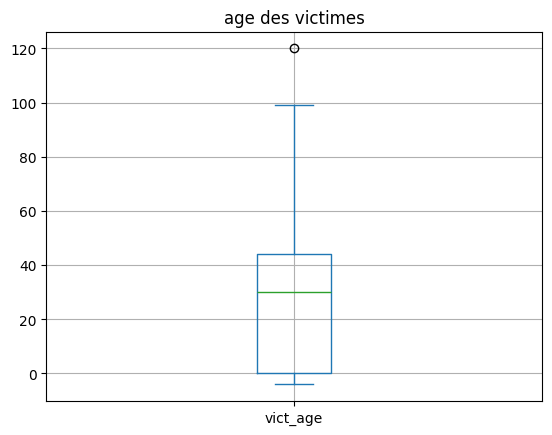

In [12]:
# Le code crée une boite a moustache qui nous montre la visualisation l'age du victimes et leur valeur

df["vict_age"].plot(kind = "box", title = "age des victimes", grid = True)
plt.show()

In [13]:
df.loc[df['vict_age'] < 0, 'vict_age'] = 0
df.loc[df['vict_age'] >= 100, 'vict_age'] = 99

# Dans le document fournis, les ages inconnu sont écrit comme 00 mais python ne prend pas 00 comme valeur. Puisque on mes 0 au lieu de 00.

In [14]:
# En regardant, on remarque qu'il na pas plus de données abérantes.

df["vict_age"].unique()

array([ 0, 47, 19, 28, 41, 25, 27, 24, 26,  8,  7, 56, 22, 23, 31, 30, 57,
       12, 46, 51, 37, 20, 29, 33, 34, 15, 65, 59,  9, 35, 50, 64, 79, 40,
       44, 32, 16, 21, 42,  6, 72, 10, 60, 36, 18, 63, 17,  5, 39, 62, 58,
       45, 54, 14, 71, 69, 49, 38, 13, 61, 43, 78, 67, 53, 11, 48, 73, 52,
       68, 81, 80,  3, 55, 89, 70, 77, 83, 91, 82, 75, 76, 74,  2, 66, 84,
        4, 87, 86, 85, 90, 99, 96, 88, 92, 94, 93, 95, 97, 98])

In [15]:
# Une methode pour regarder tous les valeur unique de la colonne Area

df["area"].unique()

# Tous est unique, il y a pas de incoherence

array([ 7,  1,  3,  9,  6, 18, 13, 19,  2, 10,  8, 20,  4, 21, 11, 12, 14,
       15,  5, 16, 17])

In [16]:
# Une methode pour regarder tous les valeur unique de la colonne du sex du victime

df["vict_sex"].unique()

# Les valeur nan et - peut etre changer à x = unknown (inconnu)

array(['M', 'X', 'F', nan, 'H', '-'], dtype=object)

In [17]:
# Une dictionnaire avec des valeur qui est utiliser pour .replace

c_vict_sex = c_vict_sex = {
    "-":"X",
    "H":"X"
}

# Les methodes dessous est utiliser pour remplacer des valeurs spécifique avec des nouvelles valeurs spécifier

df["vict_sex"] = df["vict_sex"].replace(c_vict_sex)
df.fillna({"vict_sex":"X"}, inplace=True)


# Une methode pour regarder tous les valeur unique de la colonne du sex du victime après la methode .replace et .fillna

df["vict_sex"].unique()

array(['M', 'X', 'F'], dtype=object)

In [18]:
# Une methode pour regarder tous les valeur unique de la colonne du ethnicité du victime

df["vict_descent"].unique()

# Les valeur nan et - pourrait etre changer à x = unknown (inconnu)

array(['O', 'X', 'H', 'B', 'W', nan, 'A', 'K', 'C', 'J', 'F', 'I', 'V',
       'S', 'P', 'Z', 'G', 'U', 'D', 'L', '-'], dtype=object)

In [19]:
# Les methodes dessous est utiliser pour remplacer des valeurs spécifique avec des nouvelles valeurs spécifier

df["vict_descent"] = df["vict_descent"].replace("-","X")
df.fillna({"vict_descent":"X"}, inplace=True)


# Une methode pour regarder tous les valeur unique de la colonne du ethnicité du victime après la methode .replace et .fillna

df["vict_descent"].unique()

array(['O', 'X', 'H', 'B', 'W', 'A', 'K', 'C', 'J', 'F', 'I', 'V', 'S',
       'P', 'Z', 'G', 'U', 'D', 'L'], dtype=object)

In [20]:
df['date_occ'] = pd.to_datetime(df['date_occ'],
                                  format='%m/%d/%Y %I:%M:%S %p')
df['year'] = df['date_occ'].dt.year
df['month'] = df['date_occ'].dt.month
df['day_week'] = df['date_occ'].dt.day_name()


# year, month, day_week :   Mesurent l’évolution, la saisonnalité et le rythme hebdomadaire
# heure :	                    time_occ est du texte ; l’heure entière permet l’analyse horaire
# weekend :                    	Teste directement « le week-end est-il plus touché ? »


In [21]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 982638 entries, 0 to 982637
Data columns (total 16 columns):
 #   Column          Non-Null Count   Dtype         
---  ------          --------------   -----         
 0   dr_no           982638 non-null  int64         
 1   date_occ        982638 non-null  datetime64[ns]
 2   time_occ        982638 non-null  int64         
 3   area            982638 non-null  int64         
 4   part_1_2        982638 non-null  int64         
 5   crm_cd          982638 non-null  int64         
 6   mocodes         837376 non-null  object        
 7   vict_age        982638 non-null  int64         
 8   vict_sex        982638 non-null  object        
 9   vict_descent    982638 non-null  object        
 10  premis_cd       982624 non-null  float64       
 11  weapon_used_cd  326167 non-null  float64       
 12  status          982637 non-null  object        
 13  year            982638 non-null  int32         
 14  month           982638 non-null  int

In [22]:
df.head()

,dr_no,date_occ,time_occ,area,part_1_2,crm_cd,mocodes,vict_age,vict_sex,vict_descent,premis_cd,weapon_used_cd,status,year,month,day_week
0,190326475,2020-03-01,2130,7,1,510,NaN,0,M,O,101.0,NaN,AA,2020,3,Sunday
1,200106753,2020-02-08,1800,1,1,330,1822 1402 0344,47,M,O,128.0,NaN,IC,2020,2,Saturday
2,200320258,2020-11-04,1700,3,1,480,0344 1251,19,X,X,502.0,NaN,IC,2020,11,Wednesday
3,200907217,2020-03-10,2037,9,1,343,0325 1501,19,M,O,405.0,NaN,IC,2020,3,Tuesday
4,220614831,2020-08-17,1200,6,2,354,1822 1501 0930 2004,28,M,H,102.0,NaN,IC,2020,8,Monday
